In [1]:
import numpy as np
import matplotlib.pyplot as plt
import ogstools as ot


In [3]:
def calculate_function_k_s(factors):
    pjack=factors['pjack']
    p1=factors['p1']
    p2=factors['p2']
    wr=max(factors['wr'], 1e-6)
    k01=factors['k01']
    k02=factors['k02']

    sfmax= 1.0e-6
    prev=np.linspace(p1,p2,300)

    tanh_term = np.tanh((prev - pjack) / wr)
    c=(k02 - k01) * 0.5
    k_value = k01 + c* (1 + tanh_term)

    sf0=factors['sf0']
    beta_dimen=factors['b_dim']
    beta=pjack*beta_dimen

    X= np.sqrt(3)*np.sqrt(k_value)/k_value
    Y= c*(1-tanh_term**2)/wr
    s_value= sf0 + beta*X*Y 
    s_new = sf0 + beta*X*Y/(k_value)
    s_2 = s_value.copy()

    mask = (prev<0.8*pjack)
    p_s = prev[mask]
    s_s = s_value[mask]
    pstart= p_s[0]
    pend = p_s[-1]
    w_p = (pend-p_s)/(pend-pstart)

    s_adjusted = s_s + w_p*(sf0-s_s[0])
    s_zero = s_s[0]
    s_2[mask]= s_adjusted
    sa_min = s_2.min()

    s_2 = sf0 + ((s_2 - s_2.min())/(s_2.max()-s_2.min()))*(sfmax-sf0)

    sech2_ = (1.0 - tanh_term**2)
    dk_dp = Y
    f = 1.0/np.sqrt(k_value)
    df_dp = -0.5 * (k_value**(-1.5))*dk_dp

    g = sech2_
    dg_dp = -(2.0/wr)*tanh_term*sech2_

    C0 = beta *(  np.sqrt(3.0)* (k02 - k01)/(2.0*wr))
    term_A = C0*f*dg_dp
    term_B = C0*df_dp*g
    dsraw_dp = term_A + term_B
    A =  ((sfmax - sf0)/(s_value.max()-s_value.min()))

    ds_dp = A * dsraw_dp

    # dsnum = np.gradient(s_value, prev)
    # dsnum2 = np.gradient(s_2, prev)

    # keff=k_value*s_value/sf0
    val_dict = {
        "pstart": pstart,
        "pend": pend,
        "C0"  : C0,
        "s_zero" : s_zero,
        "A"      : A, 
        "sa_min" : sa_min       
    }

    return prev, s_new,s_value #s_2, ds_dp, val_dict

In [70]:
def calculate_function_k_s_2(factors):
    pjack=factors['pjack']
    p1=factors['p1']
    p2=factors['p2']
    wr=max(factors['wr'], 1e-6)
    s_plat = factors["s_plat"]
    b_spike = factors["b_spike"]
    w_spike = factors["w_spike"]
    sf0 = factors["sf0"]
     
    factor_spike = b_spike
    hs = factor_spike *s_plat
    
    beta = 1/w_spike
    alpha = 1.0/wr
  
    prev=np.linspace(p1,p2,300)

    tanh_t1 = np.tanh( 0.5 * alpha * (prev - pjack)) 
    tanh_t2 = np.tanh ( beta * (prev - pjack))
    term_A = 0.5 * s_plat * ( 1 + tanh_t1)
    term_B = hs * ( 1 - tanh_t2**2)

    s_ab = sf0 + term_A + term_B

    ds_term_A = s_plat * ( 1- tanh_t1**2) * alpha / 4
    ds_term_B = -2 * hs * beta * tanh_t2 * (1 - tanh_t2**2)
    ds_ab = ds_term_A + ds_term_B

    ds_dp_ab_num = np.gradient(s_ab, prev)

    return prev, s_ab, ds_ab, ds_dp_ab_num

In [89]:
factors={
         'sf0':8.5e-11,
         's_plat': 1.0e-8, 
         'pjack':3.5e6,
         'wr':0.5e6,
         'w_spike': 1.0e6,
         'L':1.0,
         'b_spike': 0.5,
         'k01':2e-14,
         'k02':1.0e-9,
         'sma':1.0e-10,
         'b_dim':1.0,
         'p1':1.0,
         'p2':12.0e6,
         'keff':1.0
}

In [90]:
prev, s_ab, ds1, ds2= calculate_function_k_s_2(factors)

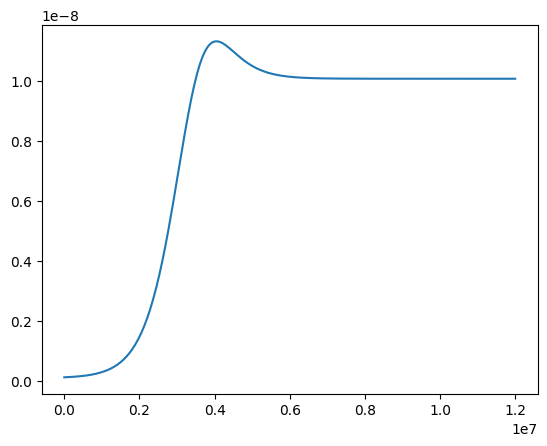

In [91]:
plt.plot(prev, s_ab)
# plt.plot(prev,ds1)
# plt.plot(prev,ds2)

plt.pause(1)

In [4]:
# pvalue, s2, ds, dsnum, dsnum2= 
prev,s2,ds_dp, val_dict = calculate_function_k_s(factors)

In [5]:
# # plt.plot(pvalue, s2)
# plt.plot(pvalue, ds)
# # plt.plot(pvalue, dsnum)
# plt.plot(pvalue, dsnum2)

# plt.pause(1)

In [6]:
def temp_prj(prj_in, prj_out,val_dict: dict, factors:dict): 

    kf=(factors['k01'] +factors['k02'])/2
    s_xml, ds_xml = ogs_expr_ready(val_dict, factors)

    model = ot.Project(input_file=prj_in,output_file=prj_out)
    medium=1
    xpath_s=f".//media/medium[@id='{medium}']/properties/property[name='storage']/value/expression"
    xpath_ds=f".//media/medium[@id='{medium}']/properties/property[name='storage']/dvalue/expression"
    try:
        model.replace_text(s_xml,xpath=xpath_s)
        model.replace_text(ds_xml,xpath=xpath_ds)
        model.replace_medium_property_value(medium,'permeability',str(kf))

        nodes = model.tree.getroot().findall(xpath_s)
        print(f"found {len(nodes)} nodes(s) matchin xpath_s")

    except Exception as e:
        print(f"CRITICAL ERROR in PRJ update: {e}")
        raise # Stop the loop if the input file is not correctly updated

    model.write_input()

In [ ]:
def wp_str(values):

    p = "liquid_phase_pressure"
    pstart = values["pstart"]
    pend = values["pend"]

    expresssion = (
                  f"((({p} < {pstart}) ? 1.0 : "
                  f"(({p} > {pend}) ? 0.0 : "
                  f"(({pend} - {p}) / ({pend} -{pstart})))))"
                  )
    return expresssion

In [ ]:
def  ogs_expr_ready(factors: dict) -> None:
    pjack=factors['pjack']
    wr=max(factors['wr'], 1e-6)
    s_plat = factors["s_plat"]
    b_spike = factors["b_spike"]
    w_spike = factors["w_spike"]
    sf0 = factors["sf0"]
        
    factor_spike = f'{b_spike}'
    hs = f'({factor_spike} *{s_plat})'
    
    beta = f'(1.0 / {w_spike})'
    alpha = f'(1.0 / {wr})'
    
    prev= "liquid_phase_pressure"

    tanh_t1 = f'(tanh( 0.5 * {alpha} * ({prev} - {pjack})))' 
    tanh_t2 = f'(tanh( {beta} * ({prev} - {pjack})))'
    term_A = f'(0.5 * {s_plat} * ( 1 + {tanh_t1}))'
    term_B = f'({hs} * ( 1 - pow({tanh_t2},2)))'

    s_ab = f'({sf0} + {term_A} + {term_B})'
    s_xml = s_ab

    ds_term_A = f'({s_plat} * ( 1- pow({tanh_t1}, 2)) * {alpha} / 4)'
    ds_term_B = f'(-2 * {hs} * {beta} * {tanh_t2} * (1 - pow({tanh_t2}, 2)))'
    ds_ab = f'({ds_term_A} + {ds_term_B})'
    ds_xml = ds_ab
       
    return s_xml, ds_xml

In [45]:
s_xml, ds_xml = ogs_expr_ready(factors)

print(s_xml)
print("\n",ds_xml)

(8.5e-11 + (0.5 * 1e-08 * ( 1 + (tanh( 0.5 * (1.0 / 500000.0) * (liquid_phase_pressure - 3500000.0))))) + ((1.0 *1e-08) * ( 1 - (tanh( (1.0 / 1000000.0) * (liquid_phase_pressure - 3500000.0)))**2)))

 ((1e-08 * ( 1- pow((tanh( 0.5 * (1.0 / 500000.0) * (liquid_phase_pressure - 3500000.0))), 2)) * (1.0 / 500000.0) / 4) + (-2 * (1.0 *1e-08) * (1.0 / 1000000.0) * (tanh( (1.0 / 1000000.0) * (liquid_phase_pressure - 3500000.0))) * (1 - pow((tanh( (1.0 / 1000000.0) * (liquid_phase_pressure - 3500000.0))), 2))))


# Testing expression


In [33]:
def eval_exprtk_in_python(script_str, params):
    clean_script = script_str.replace("&lt;", "<").replace("&gt;", ">")

    lines = [line.strip() for line in clean_script.strip().splitlines() if line.strip()]
    statements, final_expr = lines[:-1], lines[-1]

    local_scope = {**params,
                   "tanh": np.tanh,
                    "pow": np.pow,
                    "sqrt": np.sqrt}

    for line in statements:
        line = line.rstrip(";").removeprefix("var ").strip()
        var_name, expr = line.split(":=", 1)
        var_name, expr = var_name.strip(), expr.strip()

        if "?" in expr and ":" in expr:
            expr = "np.where( liquid_phase_pressure < pstart, 1.0, np.where(liquid_phase_pressure > pend, 0.0, (pend-liquid_phase_pressure) / (pend - pstart)))"

        local_scope[var_name] = eval(expr, {"__builtins__": {}, "np": np}, local_scope)

    return eval(final_expr, {"__builtins__": {}}, local_scope)

# test
# params = {
#     "liquid_phase_pressure": prev,
#     "pjack": factors["pjack"],
#     "w": factors["wr"], 
#     "k01": factors["k01"], 
#     "k02": factors["k02"],
#     "sf0": factors["sf0"], 
#     "C0": val_dict["C0"], 
#     "pstart": val_dict["pstart"], 
#     "pend": val_dict["pend"],
#     "s_zero": val_dict["s_zero"], 
#     "A": val_dict["A"], 
#     "sa_min": val_dict["sa_min"]
# }

# exprtk_val_s = eval_exprtk_in_python(str(s_xml), params)
# print("Evaluated Script Result:", exprtk_val_s)

# exprtk_val_ds = eval_exprtk_in_python(str(ds_xml), params)
# print("Evaluated Script Result:", exprtk_val_ds)
import math 
import re
import ast

class ExprTkTop(ast.NodeTransformer):
    def visit_name(self, node):
        if node.id == "liquid_phase_pressure":
            return ast.Name(id="p", ctx=node.ctx)
        elif node.id in ("tanh", "sqrt"):
            return ast.Name(id=node.id, ctx=node.ctx)
        return self.generic_visit(node)

def exptrk_eval(exp_str, p_vec):
    expr_py = exp_str.replace("&lt;", "<")
    expr_py = expr_py.replace("&gt;", ">")
    expr_py = expr_py.replace("?", " if ").replace(":", " else ")
    expr_py = expr_py.replace("liquid_phase_pressure", "p")
    tree = ast.parse(expr_py, mode = "eval")

    transformed_tree = ExprTkTop().visit(tree)
    ast.fix_missing_locations(transformed_tree)

    compile_code = compile(transformed_tree, filename="<ogs_expr>", mode="eval")

    eval_namespace = {
        "p": float(p_vec), 
        "tanh": math.tanh,
        "sqrt": math.sqrt,
    }


    return eval(compile_code, eval_namespace)


In [46]:
p_array = np.linspace(1.0,12.0e6,300)
result_s = np.array([exptrk_eval(s_xml, p) for p in p_array])
result_ds = np.array([exptrk_eval(ds_xml, p) for p in p_array])

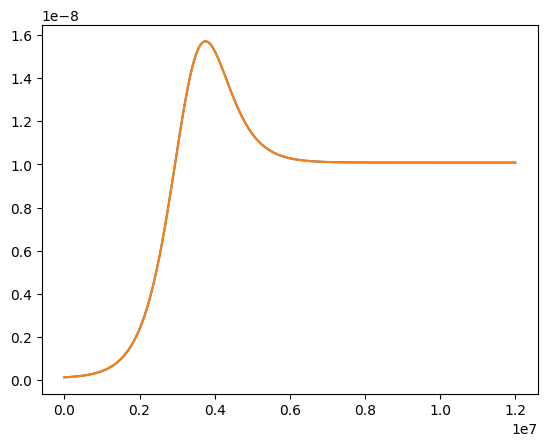

In [ ]:
plt.plot(p_array,result_s)
plt.pause(1)

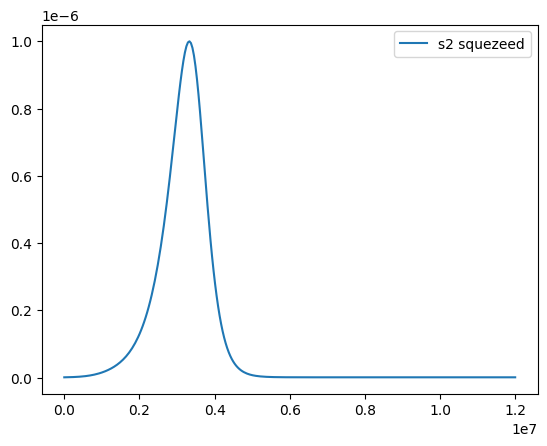

In [14]:
plt.plot(prev, s2, label = "s2 squezeed")
# plt.plot(prev, exprtk_eval, label = "ogs formula s2 squezeed")
plt.legend()
plt.pause(1)

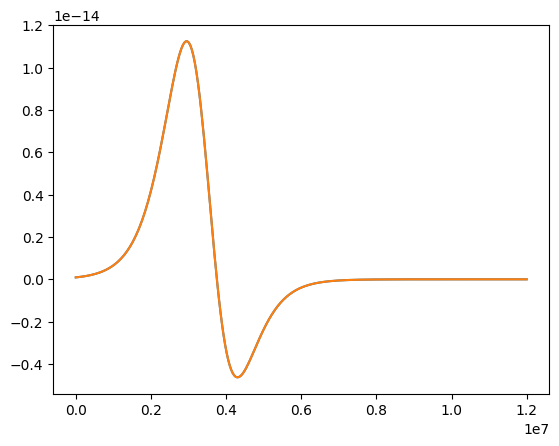

In [ ]:
plt.plot(p_array,result_ds)
plt.pause(1)

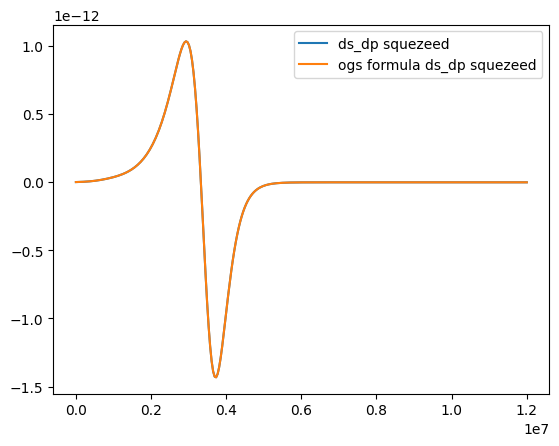

In [ ]:
plt.plot(prev, ds_dp, label = "ds_dp squezeed")
plt.plot(prev, exprtk_val_ds, label = "ogs formula ds_dp squezeed")
plt.legend()
plt.pause(1)

# Test prj mod

In [ ]:
temp_prj(prj_in="BH10_20180718_40.6_SA_sf.prj",
         prj_out="BH10_20180718_40.6_SA_sf_updated.prj",
         val_dict = val_dict,
         factors= factors)

found 1 nodes(s) matchin xpath_s
